# 07 — Data Quality and Schema Audit

> **Is the dataset reliable enough for decision support, and where are the risks?**

| | |
|---|---|
| **Audience** | Data engineers, platform reviewers |
| **Owner** | CX Complaint Intelligence team |
| **Status** | Reference implementation (portfolio sample) |
| **Last reviewed** | 2026-05-25 |
| **Runtime** | ~10 s on the bundled sample |
| **Reproduces from** | `data/raw/cfpb_sample.csv` |

## Business question

Does the normalised CFPB sample conform to the canonical schema, and where are the main data-quality risks that downstream notebooks should know about?

## How to read this notebook

1. Section **0** initialises the environment and loads data.
2. Sections **1-N** build the analysis tables and visuals.
3. The **Insights** section is generated from the computed tables &mdash; it does not contain hand-written claims.
4. The **Limitations** section flags known caveats before stakeholders act on the numbers.
5. The **Exports** section persists every table and figure under `reports/notebook/07/` so the output is auditable.


## 0. Setup

This cell:

- locates the project root from wherever the kernel was started;
- applies the shared matplotlib house style and pandas display options;
- creates the artefact directory `reports/notebook/07/`;
- captures the Python and library versions used for this run.


In [1]:
from __future__ import annotations

import warnings
from IPython.display import Markdown, display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cx_complaints.reports.notebook_utils import (
    PALETTE,
    RISK_COLORS,
    concentration_table,
    horizontal_bar,
    kpi_table,
    load_complaints,
    load_pipeline_outputs,
    monthly_summary,
    render_environment,
    save_figure,
    save_table,
    setup_notebook,
    topic_labels,
    write_environment_snapshot,
)

warnings.filterwarnings("ignore", category=FutureWarning)

ctx = setup_notebook("07")
render_environment(ctx)


,field,value
0,python,3.12.11
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.4.6
3,pandas,2.3.3
4,matplotlib,3.10.9
5,scikit-learn,1.8.0
6,project_root,C:\Users\diogo\work_code\portfolio\cx-complain...
7,notebook_id,07


## 1. Load the raw and normalised frames

In [2]:
from cx_complaints.data.schema import CANONICAL_COLUMNS, normalize_complaints

raw_path = ctx.data_raw / "cfpb_sample.csv"
raw = pd.read_csv(raw_path)
complaints = normalize_complaints(raw)
print(f"Raw rows:        {len(raw):,}")
print(f"Normalised rows: {len(complaints):,}")
print(f"Canonical columns: {len(CANONICAL_COLUMNS)}")

Raw rows:        1,000
Normalised rows: 1,000
Canonical columns: 19


## 2. Schema conformance

In [3]:
schema_check = pd.DataFrame({
    "column": list(CANONICAL_COLUMNS),
    "present": [column in complaints.columns for column in CANONICAL_COLUMNS],
    "dtype": [
        str(complaints[column].dtype) if column in complaints.columns else "missing"
        for column in CANONICAL_COLUMNS
    ],
})
schema_check

,column,present,dtype
0,complaint_id,True,Int64
1,date_received,True,"datetime64[ns, UTC-05:00]"
2,product,True,string
3,sub_product,True,string
4,issue,True,string
5,sub_issue,True,string
6,complaint_what_happened,True,string
7,company_public_response,True,string
8,company,True,string
9,state,True,string


## 3. Integrity checks

In [4]:
duplicate_ids = int(complaints["complaint_id"].duplicated(keep=False).sum())
missing_ids = int(complaints["complaint_id"].isna().sum())
invalid_dates = int(complaints["date_received"].isna().sum())
integrity = pd.DataFrame({
    "check": [
        "Duplicate complaint_id rows",
        "Missing/invalid date_received rows",
        "Missing complaint_id rows",
    ],
    "count": [duplicate_ids, invalid_dates, missing_ids],
})
integrity

,check,count
0,Duplicate complaint_id rows,0
1,Missing/invalid date_received rows,0
2,Missing complaint_id rows,0


## 4. Missingness profile

In [5]:
missingness = pd.DataFrame({
    "column": complaints.columns,
    "missing_count": complaints.isna().sum().values,
})
missingness["missing_pct"] = (missingness["missing_count"] / len(complaints) * 100).round(2)
missingness = missingness.sort_values("missing_pct", ascending=False).reset_index(drop=True)
missingness.head(20)

,column,missing_count,missing_pct
0,has_narrative,1000,100.00
1,consumer_disputed,1000,100.00
2,tags,946,94.60
3,company_public_response,394,39.40
4,sub_issue,23,2.30
5,state,1,0.10
6,complaint_id,0,0.00
7,product,0,0.00
8,date_received,0,0.00
9,complaint_what_happened,0,0.00


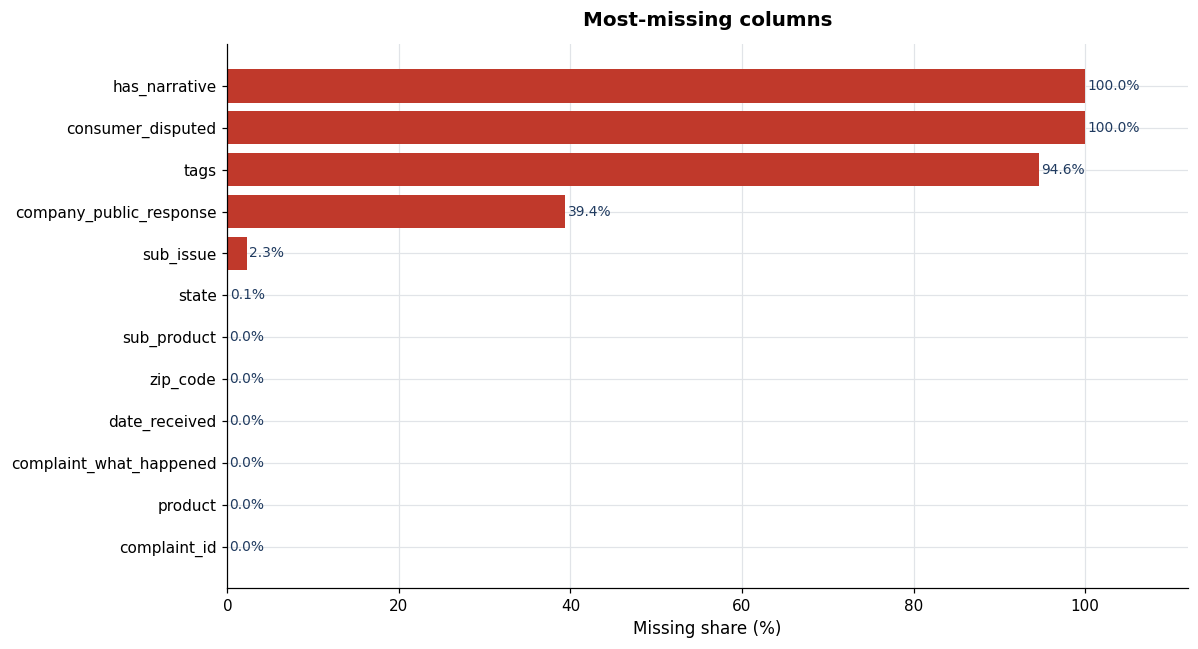

In [6]:
top_missing = missingness.head(12)
fig, ax = plt.subplots(figsize=(11, 6))
horizontal_bar(
    ax, top_missing["column"], top_missing["missing_pct"],
    color=PALETTE["warning"], value_format="{:.1f}%",
)
ax.set_title("Most-missing columns")
ax.set_xlabel("Missing share (%)")
fig.tight_layout()
save_figure(ctx, fig, "missingness_top12")
plt.show()

## 5. Narrative availability over time

In [7]:
with_dates = complaints.dropna(subset=["date_received"]).copy()
with_dates["month"] = with_dates["date_received"].dt.to_period("M").astype(str)
narrative_monthly = (
    with_dates.groupby("month", as_index=False)
    .agg(
        complaints=("complaint_id", "size"),
        narrative_share_pct=(
            "has_narrative",
            lambda series: series.fillna(False).astype(bool).mean() * 100,
        ),
    )
    .sort_values("month")
)
narrative_monthly["narrative_share_pct"] = narrative_monthly["narrative_share_pct"].round(2)
narrative_monthly

C:\Users\diogo\AppData\Local\Temp\ipykernel_28320\2054089455.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  with_dates["month"] = with_dates["date_received"].dt.to_period("M").astype(str)


,month,complaints,narrative_share_pct
0,2024-06,1000,False


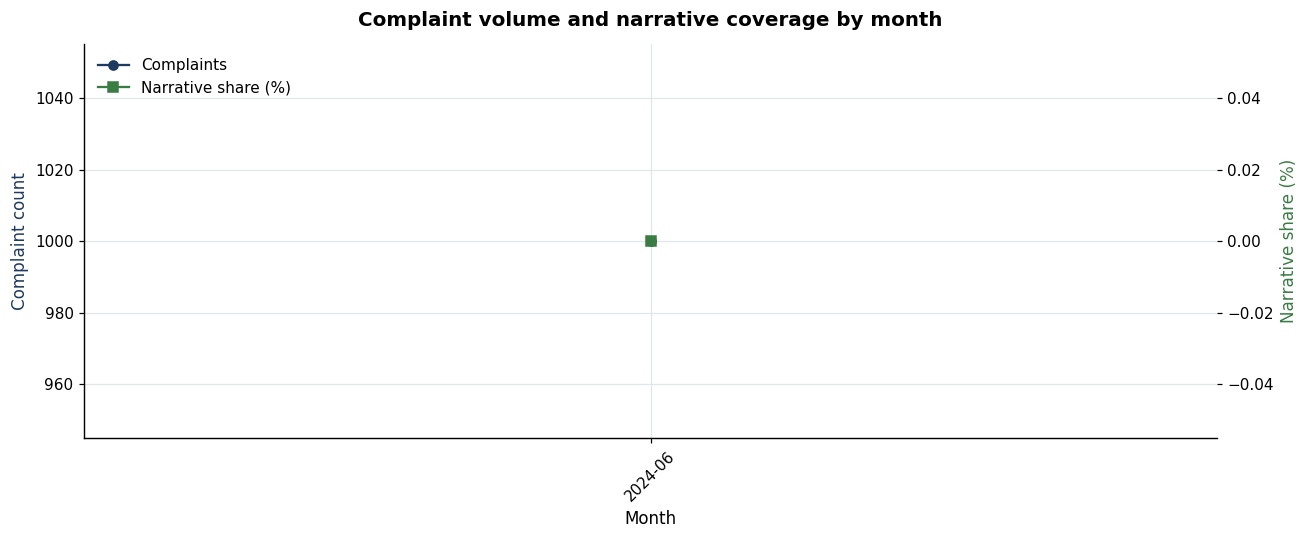

In [8]:
fig, ax_volume = plt.subplots(figsize=(12, 5))
ax_narr = ax_volume.twinx()
ax_narr.grid(False)
ax_volume.plot(
    narrative_monthly["month"], narrative_monthly["complaints"],
    marker="o", color=PALETTE["primary"], label="Complaints",
)
ax_narr.plot(
    narrative_monthly["month"], narrative_monthly["narrative_share_pct"],
    marker="s", color=PALETTE["positive"], label="Narrative share (%)",
)
ax_volume.set_title("Complaint volume and narrative coverage by month")
ax_volume.set_xlabel("Month")
ax_volume.set_ylabel("Complaint count", color=PALETTE["primary"])
ax_narr.set_ylabel("Narrative share (%)", color=PALETTE["positive"])
ax_volume.tick_params(axis="x", rotation=45)
lines_v, labels_v = ax_volume.get_legend_handles_labels()
lines_n, labels_n = ax_narr.get_legend_handles_labels()
ax_volume.legend(lines_v + lines_n, labels_v + labels_n, loc="upper left")
fig.tight_layout()
save_figure(ctx, fig, "narrative_coverage_monthly")
plt.show()

## 6. Insights

In [9]:
narrative_share_now = float(narrative_monthly["narrative_share_pct"].iloc[-1])
most_missing = missingness.iloc[0]
schema_gaps = schema_check[~schema_check["present"]]
gap_text = "" if schema_gaps.empty else (
    f"- **Schema gaps**: missing columns {list(schema_gaps['column'])} (added as null by the normaliser).\n"
)
narrative = (
    f"- **ID integrity**: {duplicate_ids} duplicate IDs, {missing_ids} missing IDs.\n"
    f"- **Date integrity**: {invalid_dates} unparseable `date_received` values.\n"
    f"- **Top missing field**: `{most_missing['column']}` ({most_missing['missing_pct']:.1f}% null).\n"
    f"- **Narrative coverage** (latest month): {narrative_share_now:.1f}%. "
    "NLP-heavy notebooks (02, 06, 09, 10) rely on this share staying high.\n"
    f"{gap_text}"
)
display(Markdown(narrative))

- **ID integrity**: 0 duplicate IDs, 0 missing IDs.
- **Date integrity**: 0 unparseable `date_received` values.
- **Top missing field**: `has_narrative` (100.0% null).
- **Narrative coverage** (latest month): 0.0%. NLP-heavy notebooks (02, 06, 09, 10) rely on this share staying high.


## Limitations

- The risk score is heuristic, not a legal or regulatory finding. It exists to triage analyst attention.
- CFPB narratives are only published when the consumer consents, so coverage is partial.
- Company-level comparisons mix companies of very different sizes &mdash; always pair them with volume context.
- The sample bundled with this repo is a small subset of the public CFPB dataset and is meant for demonstration, not production decisions.

## Exports

All tables and figures generated above are saved under `reports/notebook/07/`. The environment snapshot is written alongside so a reader can reproduce the run.


In [10]:
save_table(ctx, schema_check, "schema_check")
save_table(ctx, integrity, "integrity_summary")
save_table(ctx, missingness, "missingness_profile")
save_table(ctx, narrative_monthly, "narrative_monthly")
write_environment_snapshot(ctx)
sorted(ctx.artefact_dir.iterdir())

[WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/07/environment.json'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/07/integrity_summary.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/07/missingness_profile.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/07/missingness_top12.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/07/narrative_coverage_monthly.png'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/07/narrative_monthly.csv'),
 WindowsPath('C:/Users/diogo/work_code/portfolio/cx-complaint-intelligence/reports/notebook/07/schema_check.csv')]